In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import learning_curve

# Exploratory Data Analysis (EDA)

***Global AI & Data Jobs Salary Dataset:***

*   **id**

*   **country**

*   **job_role:**   Job title

*   **ai_specialization:** AI sub-domain focus

*   **Expericenc_level:**   Career stage

*   **experience_years**

*   **salary_usd**

*   **bonus_usd**

*   **education_required:**	Minimum education required.

*   **industry:**   Employer's industry sector.

*   **company_size**

*   **interview_rounds**

*   **year:**   Years in service.

*   **work_mode:**   Work arrangement.

*   **weekly_hours:**   Average weekly working hours.

*   **company_rating:**   Employer rating on a scale of 1–5.

*   **job_openings:**   Number of open positions for the role.

*   **hiring_difficulty_score**

*   **layoff_risk:**   Work arrangement

*   **ai_adoption_score**   

*   **company_funding_billion:**   Total funding raised by company in billions USD.

*   **economic_index**

*   **ai_maturity_years**

*   **offer_acceptance_rate**

*   **tax_rate_percent**

*   **vacation_days**

*   **skill_demand_score:**     Demand score for the role's required skills.

*   **automation_risk:**     Risk of the role being automated.

*   **job_security_score**

*   **career_growth_score**

*   **work_life_balance_score**

*   **promotion_speed**

*   **salary_percentile**

*   **cost_of_living_index**

*   **employee_satisfaction**


In [ ]:
df = pd.read_csv('global_ai_jobs.csv')
df.head(10)

,id,country,job_role,ai_specialization,experience_level,experience_years,salary_usd,bonus_usd,education_required,industry,...,vacation_days,skill_demand_score,automation_risk,job_security_score,career_growth_score,work_life_balance_score,promotion_speed,salary_percentile,cost_of_living_index,employee_satisfaction
0,1,UAE,Machine Learning Engineer,Reinforcement Learning,Entry,0,66465,5395,Master,Automotive,...,27,12,76,57,65,73,15,55,1.23,76
1,2,USA,AI Engineer,LLM,Entry,1,75507,11713,Bootcamp,Retail,...,27,54,29,69,60,51,15,58,0.87,67
2,3,Brazil,Research Scientist,Analytics,Entry,0,41660,5268,PhD,Healthcare,...,13,12,49,70,59,68,37,13,2.13,61
3,4,India,Software Engineer AI,Computer Vision,Senior,6,43268,7975,Diploma,Tech,...,30,80,47,79,65,55,46,74,1.49,56
4,5,Germany,Machine Learning Engineer,Computer Vision,Entry,0,69119,4758,Master,Retail,...,24,82,47,64,52,69,17,21,0.87,72
5,6,India,Software Engineer AI,NLP,Mid,3,37712,3964,Bootcamp,Automotive,...,24,49,35,55,37,48,38,82,2.44,63
6,7,Japan,Data Analyst,LLM,Senior,9,71014,11956,PhD,Tech,...,16,73,92,93,42,96,67,41,1.57,80
7,8,Germany,Computer Vision Engineer,MLOps,Lead,19,194659,14720,Master,Consulting,...,27,34,96,84,66,77,57,75,2.43,81
8,9,Australia,NLP Engineer,Forecasting,Senior,10,153176,24144,Bachelor,Retail,...,30,21,88,79,56,56,50,55,1.99,85
9,10,Brazil,Machine Learning Engineer,Forecasting,Lead,19,102716,17724,Bootcamp,Telecom,...,13,88,69,84,66,86,31,97,0.85,83


In [ ]:
df.shape

(90000, 35)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 35 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       90000 non-null  int64  
 1   country                  90000 non-null  object 
 2   job_role                 90000 non-null  object 
 3   ai_specialization        90000 non-null  object 
 4   experience_level         90000 non-null  object 
 5   experience_years         90000 non-null  int64  
 6   salary_usd               90000 non-null  int64  
 7   bonus_usd                90000 non-null  int64  
 8   education_required       90000 non-null  object 
 9   industry                 90000 non-null  object 
 10  company_size             90000 non-null  object 
 11  interview_rounds         90000 non-null  int64  
 12  year                     90000 non-null  int64  
 13  work_mode                90000 non-null  object 
 14  weekly_hours          

In [ ]:
df.describe(include='all')

,id,country,job_role,ai_specialization,experience_level,experience_years,salary_usd,bonus_usd,education_required,industry,...,vacation_days,skill_demand_score,automation_risk,job_security_score,career_growth_score,work_life_balance_score,promotion_speed,salary_percentile,cost_of_living_index,employee_satisfaction
count,90000.000000,90000,90000,90000,90000,90000.000000,90000.000000,90000.000000,90000,90000,...,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000,90000.000000
unique,NaN,12,8,8,4,NaN,NaN,NaN,5,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Canada,NLP Engineer,Computer Vision,Senior,NaN,NaN,NaN,Bootcamp,Gaming,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,7602,11412,11487,22680,NaN,NaN,NaN,18148,9190,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,45000.500000,NaN,NaN,NaN,NaN,7.028133,96546.249222,13028.418722,NaN,NaN,...,19.986367,50.461200,50.357544,75.563533,57.198544,69.146478,38.439633,50.542411,1.503042,72.733100
std,25980.906451,NaN,NaN,NaN,NaN,5.889327,43935.479553,7886.738085,NaN,NaN,...,6.069607,28.853798,28.845671,11.316485,12.900225,13.213996,18.429221,28.891570,0.576449,8.124018
min,1.000000,NaN,NaN,NaN,NaN,0.000000,28000.000000,1404.000000,NaN,NaN,...,10.000000,1.000000,1.000000,29.000000,25.000000,25.000000,12.000000,1.000000,0.500000,42.000000
25%,22500.750000,NaN,NaN,NaN,NaN,2.000000,64676.750000,7104.750000,NaN,NaN,...,15.000000,25.000000,25.000000,68.000000,48.000000,59.000000,24.000000,25.000000,1.010000,67.000000
50%,45000.500000,NaN,NaN,NaN,NaN,6.000000,87544.000000,11279.000000,NaN,NaN,...,20.000000,51.000000,50.000000,77.000000,57.000000,69.000000,37.000000,51.000000,1.510000,73.000000
75%,67500.250000,NaN,NaN,NaN,NaN,12.000000,123906.000000,16997.250000,NaN,NaN,...,25.000000,75.000000,75.000000,84.000000,66.000000,79.000000,51.000000,76.000000,2.000000,78.000000


In [ ]:
df.nunique()

,0
id,90000
country,12
job_role,8
ai_specialization,8
experience_level,4
experience_years,20
salary_usd,65976
bonus_usd,27544
education_required,5
industry,10


In [ ]:
missing = df.isnull().sum()
print(missing)
print(f'\nTotal missing values: {missing.sum()}')

id                         0
country                    0
job_role                   0
ai_specialization          0
experience_level           0
experience_years           0
salary_usd                 0
bonus_usd                  0
education_required         0
industry                   0
company_size               0
interview_rounds           0
year                       0
work_mode                  0
weekly_hours               0
company_rating             0
job_openings               0
hiring_difficulty_score    0
layoff_risk                0
ai_adoption_score          0
company_funding_billion    0
economic_index             0
ai_maturity_years          0
offer_acceptance_rate      0
tax_rate_percent           0
vacation_days              0
skill_demand_score         0
automation_risk            0
job_security_score         0
career_growth_score        0
work_life_balance_score    0
promotion_speed            0
salary_percentile          0
cost_of_living_index       0
employee_satis

In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print('Categorical Variables:')
print(cat_cols)
print('\nNumerical Variables:')
print(num_cols)

Categorical Variables:
['country', 'job_role', 'ai_specialization', 'experience_level', 'education_required', 'industry', 'company_size', 'work_mode']

Numerical Variables:
['id', 'experience_years', 'salary_usd', 'bonus_usd', 'interview_rounds', 'year', 'weekly_hours', 'company_rating', 'job_openings', 'hiring_difficulty_score', 'layoff_risk', 'ai_adoption_score', 'company_funding_billion', 'economic_index', 'ai_maturity_years', 'offer_acceptance_rate', 'tax_rate_percent', 'vacation_days', 'skill_demand_score', 'automation_risk', 'job_security_score', 'career_growth_score', 'work_life_balance_score', 'promotion_speed', 'salary_percentile', 'cost_of_living_index', 'employee_satisfaction']


experience_level
Senior    22680
Lead      22556
Mid       22459
Entry     22305
Name: count, dtype: int64


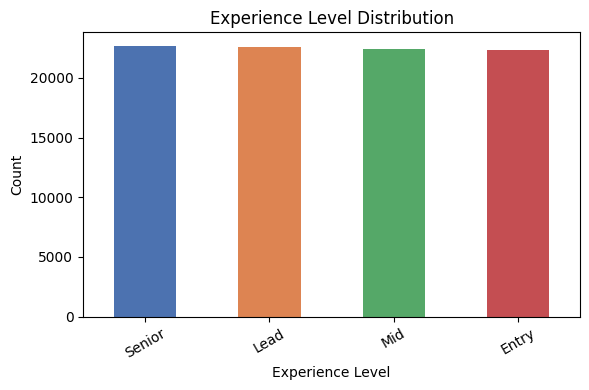

In [ ]:
print(df['experience_level'].value_counts())

plt.figure(figsize=(6, 4))
df['experience_level'].value_counts().plot(kind='bar',
    color=['#4C72B0','#DD8452','#55A868','#C44E52'])
plt.title('Experience Level Distribution')
plt.xlabel('Experience Level')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

work_mode
Onsite    30233
Remote    30005
Hybrid    29762
Name: count, dtype: int64


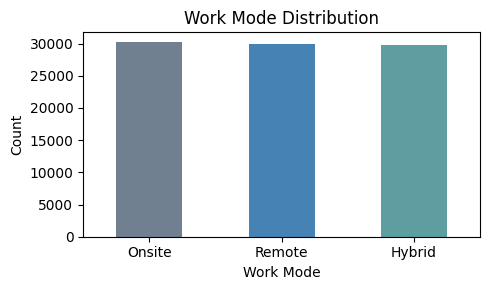

In [ ]:
print(df['work_mode'].value_counts())

plt.figure(figsize=(5, 3))
df['work_mode'].value_counts().plot(kind='bar',
    color=['slategrey','steelblue','cadetblue'])
plt.title('Work Mode Distribution')
plt.xlabel('Work Mode')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

job_role
NLP Engineer                 11412
Software Engineer AI         11333
Research Scientist           11309
Machine Learning Engineer    11263
AI Engineer                  11247
Computer Vision Engineer     11227
Data Scientist               11146
Data Analyst                 11063
Name: count, dtype: int64


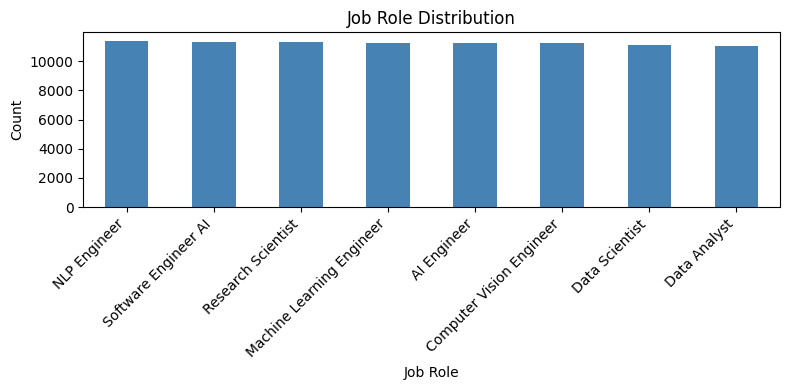

In [ ]:
print(df['job_role'].value_counts())

plt.figure(figsize=(8, 4))
df['job_role'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Job Role Distribution')
plt.xlabel('Job Role')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

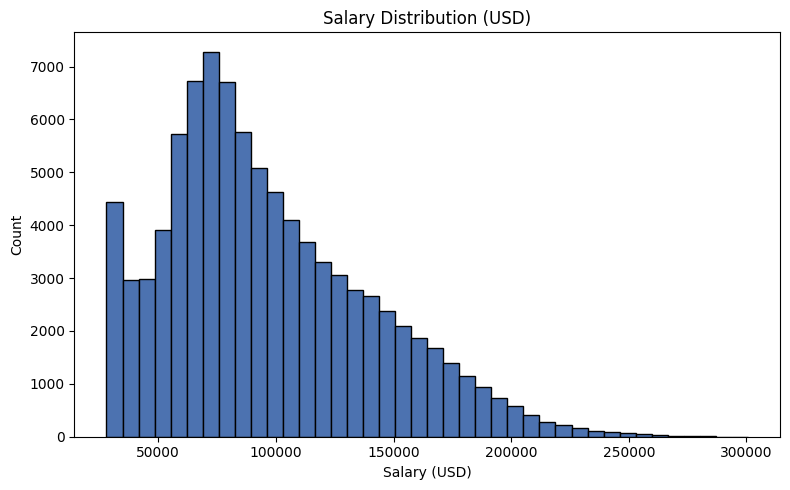

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['salary_usd'], bins=40, edgecolor='black', color='#4C72B0')
plt.title('Salary Distribution (USD)')
plt.xlabel('Salary (USD)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

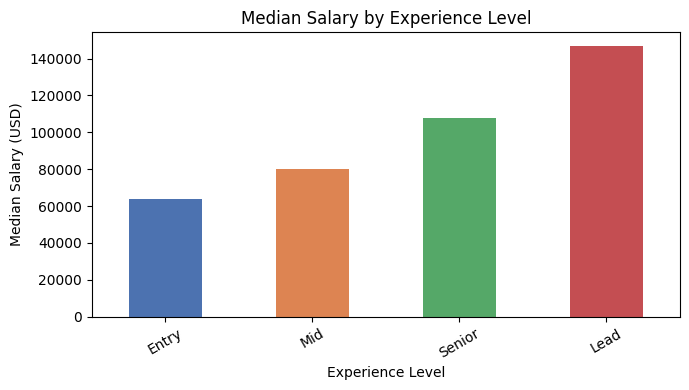

In [ ]:
plt.figure(figsize=(7, 4))
order = ['Entry', 'Mid', 'Senior', 'Lead']
df.groupby('experience_level')['salary_usd'].median().reindex(order).plot(
    kind='bar', color=['#4C72B0','#DD8452','#55A868','#C44E52'])
plt.title('Median Salary by Experience Level')
plt.xlabel('Experience Level')
plt.ylabel('Median Salary (USD)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

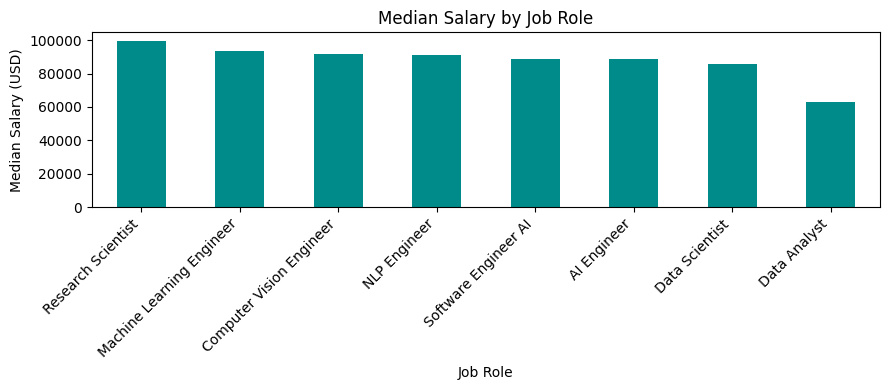

In [ ]:
plt.figure(figsize=(9, 4))
df.groupby('job_role')['salary_usd'].median().sort_values(ascending=False).plot(
    kind='bar', color='darkcyan')
plt.title('Median Salary by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Median Salary (USD)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

country
Canada         7602
Australia      7589
Singapore      7583
Brazil         7545
UK             7532
UAE            7529
Netherlands    7514
Germany        7461
India          7450
France         7440
USA            7405
Japan          7350
Name: count, dtype: int64


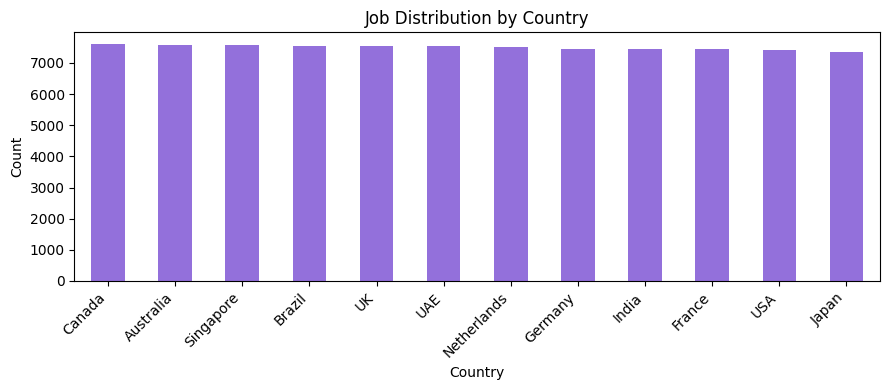

In [ ]:
print(df['country'].value_counts())

plt.figure(figsize=(9, 4))
df['country'].value_counts().plot(kind='bar', color='mediumpurple')
plt.title('Job Distribution by Country')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<Figure size 700x400 with 0 Axes>

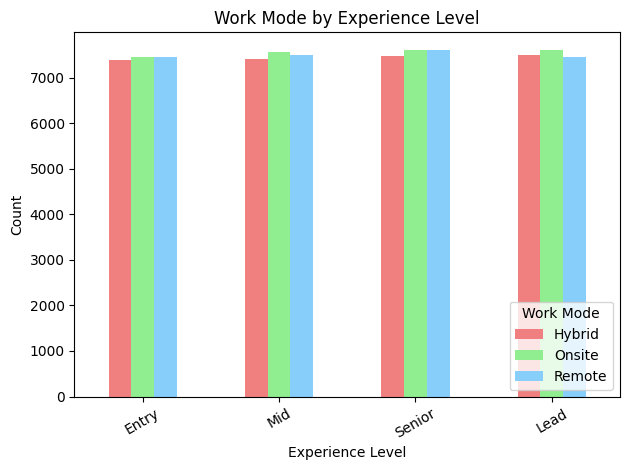

In [ ]:
plt.figure(figsize=(7, 4))
pd.crosstab(df['experience_level'], df['work_mode']).reindex(
    ['Entry','Mid','Senior','Lead']).plot(
    kind='bar', color=['lightcoral','lightgreen','lightskyblue'])
plt.title('Work Mode by Experience Level')
plt.xlabel('Experience Level')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.legend(title='Work Mode', loc='lower right')
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

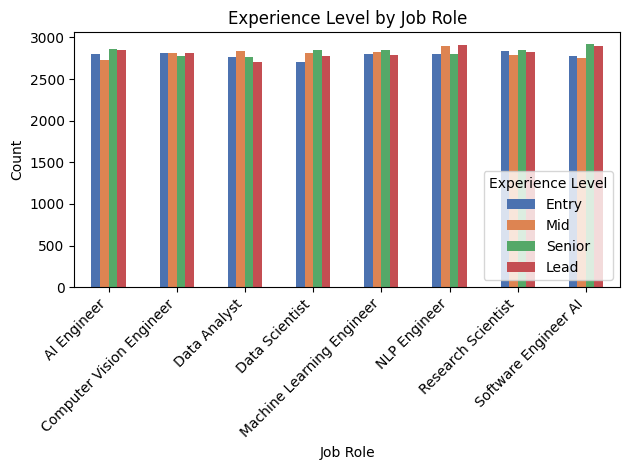

In [ ]:
plt.figure(figsize=(10, 5))
pd.crosstab(df['job_role'], df['experience_level'])[['Entry','Mid','Senior','Lead']].plot(
    kind='bar', color=['#4C72B0','#DD8452','#55A868','#C44E52'])
plt.title('Experience Level by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Experience Level', loc='lower right')
plt.tight_layout()
plt.show()

                               id  experience_years  salary_usd  bonus_usd  \
id                       1.000000          0.001841    0.007894   0.003261   
experience_years         0.001841          1.000000    0.723879   0.545966   
salary_usd               0.007894          0.723879    1.000000   0.752046   
bonus_usd                0.003261          0.545966    0.752046   1.000000   
interview_rounds        -0.003397         -0.005699   -0.006230  -0.000935   
year                     0.003830          0.000253   -0.001309   0.002574   
weekly_hours            -0.002532         -0.004406   -0.004970  -0.002344   
company_rating          -0.004251          0.004693   -0.000347   0.001736   
job_openings             0.001834          0.000691    0.003853   0.004792   
hiring_difficulty_score  0.000831          0.001893   -0.000759  -0.000395   
layoff_risk             -0.001771         -0.736261   -0.533439  -0.400488   
ai_adoption_score       -0.002036          0.011152    0.006550 

/tmp/ipykernel_6683/2964496603.py:11: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


<Figure size 1400x1200 with 0 Axes>

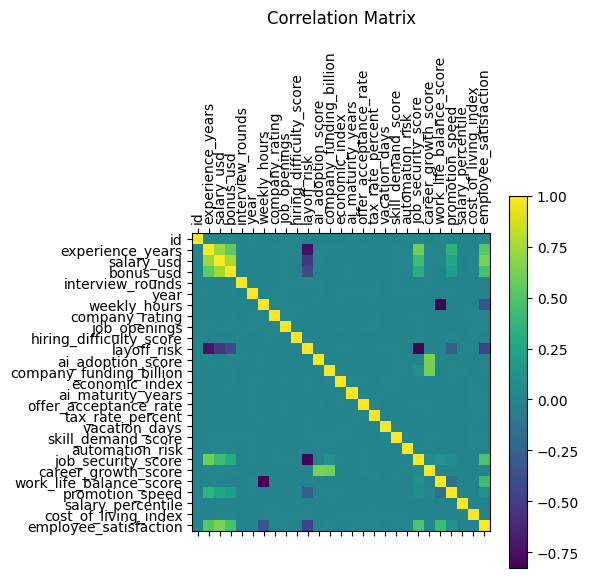

In [ ]:
plt.figure(figsize=(14, 12))
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)
plt.matshow(correlation_matrix)
plt.title('Correlation Matrix', pad=20)
plt.xticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)),
           correlation_matrix.columns)
plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
df = df.drop(['id'], axis=1)
df.shape

(90000, 34)

In [ ]:
df = df.drop_duplicates()
print(f'Shape after dropping duplicates: {df.shape}')
df.head()

Shape after dropping duplicates: (90000, 34)


,country,job_role,ai_specialization,experience_level,experience_years,salary_usd,bonus_usd,education_required,industry,company_size,...,vacation_days,skill_demand_score,automation_risk,job_security_score,career_growth_score,work_life_balance_score,promotion_speed,salary_percentile,cost_of_living_index,employee_satisfaction
0,UAE,Machine Learning Engineer,Reinforcement Learning,Entry,0,66465,5395,Master,Automotive,Small,...,27,12,76,57,65,73,15,55,1.23,76
1,USA,AI Engineer,LLM,Entry,1,75507,11713,Bootcamp,Retail,Small,...,27,54,29,69,60,51,15,58,0.87,67
2,Brazil,Research Scientist,Analytics,Entry,0,41660,5268,PhD,Healthcare,Large,...,13,12,49,70,59,68,37,13,2.13,61
3,India,Software Engineer AI,Computer Vision,Senior,6,43268,7975,Diploma,Tech,Large,...,30,80,47,79,65,55,46,74,1.49,56
4,Germany,Machine Learning Engineer,Computer Vision,Entry,0,69119,4758,Master,Retail,Medium,...,24,82,47,64,52,69,17,21,0.87,72


In [ ]:
print(df.isnull().sum())
print(f'\nTotal missing values: {df.isnull().sum().sum()}')

country                    0
job_role                   0
ai_specialization          0
experience_level           0
experience_years           0
salary_usd                 0
bonus_usd                  0
education_required         0
industry                   0
company_size               0
interview_rounds           0
year                       0
work_mode                  0
weekly_hours               0
company_rating             0
job_openings               0
hiring_difficulty_score    0
layoff_risk                0
ai_adoption_score          0
company_funding_billion    0
economic_index             0
ai_maturity_years          0
offer_acceptance_rate      0
tax_rate_percent           0
vacation_days              0
skill_demand_score         0
automation_risk            0
job_security_score         0
career_growth_score        0
work_life_balance_score    0
promotion_speed            0
salary_percentile          0
cost_of_living_index       0
employee_satisfaction      0
dtype: int64



In [ ]:
# One-Hot Encoding (categorical features, excluding target column)
df_encoded = pd.get_dummies(df, columns=[
    'country', 'job_role', 'ai_specialization',
    'education_required', 'industry', 'company_size', 'work_mode'
])
print(f'Shape after encoding: {df_encoded.shape}')
df_encoded.head()

Shape after encoding: (90000, 78)


,experience_level,experience_years,salary_usd,bonus_usd,interview_rounds,year,weekly_hours,company_rating,job_openings,hiring_difficulty_score,...,industry_Tech,industry_Telecom,company_size_Enterprise,company_size_Large,company_size_Medium,company_size_Small,company_size_Startup,work_mode_Hybrid,work_mode_Onsite,work_mode_Remote
0,Entry,0,66465,5395,7,2020,44.7,3.67,10,52.765351,...,False,False,False,False,False,True,False,False,False,True
1,Entry,1,75507,11713,3,2021,48.9,4.26,27,53.114580,...,False,False,False,False,False,True,False,False,True,False
2,Entry,0,41660,5268,3,2020,46.8,4.78,10,76.395263,...,False,False,False,True,False,False,False,False,False,True
3,Senior,6,43268,7975,2,2026,52.2,4.34,23,59.340199,...,True,False,False,True,False,False,False,False,True,False
4,Entry,0,69119,4758,2,2021,46.7,4.49,17,72.301128,...,False,False,False,False,True,False,False,True,False,False


# Preprocessing & Baseline Model Implementation

## Data Preprocessing

In [ ]:
# Separate target BEFORE any further transforms
exp_order = ['Entry', 'Mid', 'Senior', 'Lead']
le = LabelEncoder()
le.fit(exp_order)

y = le.transform(df['experience_level'])
print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print("y distribution:", dict(zip(*np.unique(y, return_counts=True))))

Class mapping: {np.str_('Entry'): np.int64(0), np.str_('Lead'): np.int64(1), np.str_('Mid'): np.int64(2), np.str_('Senior'): np.int64(3)}
y distribution: {np.int64(0): np.int64(22305), np.int64(1): np.int64(22556), np.int64(2): np.int64(22459), np.int64(3): np.int64(22680)}


In [ ]:
# Use the already one-hot-encoded dataframe (experience_level was NOT encoded there)
# Drop original experience_level column to get the feature matrix
X = df_encoded.drop(columns=['experience_level'], errors='ignore')

# Also drop salary_percentile to avoid data leakage (it encodes seniority directly)
leakage_cols = [c for c in X.columns if 'salary_percentile' in c]
X = X.drop(columns=leakage_cols, errors='ignore')

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape:  {y.shape}")
X.head()

Feature matrix shape: (90000, 76)
Target vector shape:  (90000,)


,experience_years,salary_usd,bonus_usd,interview_rounds,year,weekly_hours,company_rating,job_openings,hiring_difficulty_score,layoff_risk,...,industry_Tech,industry_Telecom,company_size_Enterprise,company_size_Large,company_size_Medium,company_size_Small,company_size_Startup,work_mode_Hybrid,work_mode_Onsite,work_mode_Remote
0,0,66465,5395,7,2020,44.7,3.67,10,52.765351,0.404,...,False,False,False,False,False,True,False,False,False,True
1,1,75507,11713,3,2021,48.9,4.26,27,53.114580,0.387,...,False,False,False,False,False,True,False,False,True,False
2,0,41660,5268,3,2020,46.8,4.78,10,76.395263,0.415,...,False,False,False,True,False,False,False,False,False,True
3,6,43268,7975,2,2026,52.2,4.34,23,59.340199,0.115,...,True,False,False,True,False,False,False,False,True,False
4,0,69119,4758,2,2021,46.7,4.49,17,72.301128,0.311,...,False,False,False,False,True,False,False,True,False,False


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test  shape:", y_test.shape)

X_train shape: (72000, 76)
X_test  shape: (18000, 76)
y_train shape: (72000,)
y_test  shape: (18000,)


In [ ]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit on train, transform train
X_test_sc  = scaler.transform(X_test)        # transform test with same scaler

print("Scaling complete. Mean (first 5 features):", X_train_sc.mean(axis=0)[:5].round(4))

Scaling complete. Mean (first 5 features): [ 0. -0.  0.  0. -0.]


---
## Baseline Model Implementation

Three baseline classifiers are trained and evaluated on the test set.


In [ ]:
# Dictionary to collect all model results
results = {}

def evaluate_model(name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0)
    results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}  (macro)")
    print(f"  Recall   : {rec:.4f}  (macro)")
    print(f"  F1-Score : {f1:.4f}  (macro)")
    print()
    print(classification_report(y_true, y_pred,
                                 target_names=le.classes_, zero_division=0))

### Baseline Model 1 — Logistic Regression

In [ ]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_sc, y_train)

y_pred_lr = lr_model.predict(X_test_sc)
evaluate_model('Logistic Regression', y_test, y_pred_lr)


  Logistic Regression
  Accuracy : 0.9987
  Precision: 0.9987  (macro)
  Recall   : 0.9987  (macro)
  F1-Score : 0.9987  (macro)

              precision    recall  f1-score   support

       Entry       1.00      1.00      1.00      4461
        Lead       1.00      1.00      1.00      4511
         Mid       1.00      1.00      1.00      4492
      Senior       1.00      1.00      1.00      4536

    accuracy                           1.00     18000
   macro avg       1.00      1.00      1.00     18000
weighted avg       1.00      1.00      1.00     18000



### Baseline Model 2 — K-Nearest Neighbours (KNN)

Best k from 5-fold CV: 39  (accuracy = 0.7213)


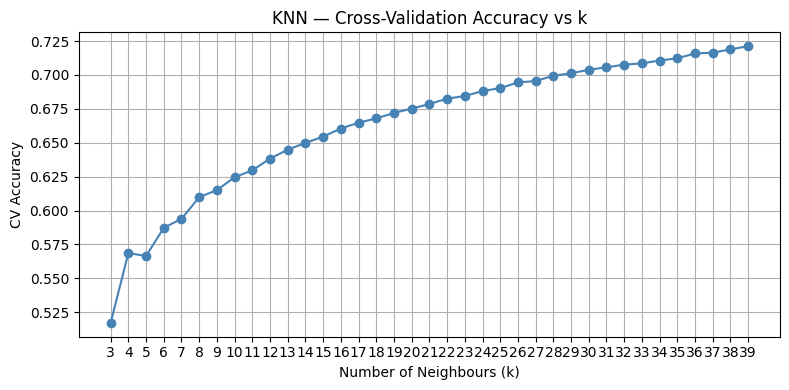

In [ ]:
# Quick cross-validation to pick the best k
k_values = range(3, 40)
cv_scores = []

for k in k_values:
    knn_cv = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    score = cross_val_score(knn_cv, X_train_sc, y_train, cv=5, scoring='accuracy').mean()
    cv_scores.append(score)

best_k = k_values[np.argmax(cv_scores)]
print(f"Best k from 5-fold CV: {best_k}  (accuracy = {max(cv_scores):.4f})")

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), cv_scores, marker='o', color='steelblue')
plt.xlabel('Number of Neighbours (k)')
plt.ylabel('CV Accuracy')
plt.title('KNN — Cross-Validation Accuracy vs k')
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_model.fit(X_train_sc, y_train)

y_pred_knn = knn_model.predict(X_test_sc)
evaluate_model('KNN', y_test, y_pred_knn)


  KNN
  Accuracy : 0.7199
  Precision: 0.7205  (macro)
  Recall   : 0.7207  (macro)
  F1-Score : 0.7200  (macro)

              precision    recall  f1-score   support

       Entry       0.86      0.91      0.89      4461
        Lead       0.79      0.72      0.76      4511
         Mid       0.65      0.69      0.67      4492
      Senior       0.57      0.56      0.57      4536

    accuracy                           0.72     18000
   macro avg       0.72      0.72      0.72     18000
weighted avg       0.72      0.72      0.72     18000



### Baseline Model 3 — Decision Tree

In [ ]:
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)   # Decision Trees do not require scaling

y_pred_dt = dt_model.predict(X_test)
evaluate_model('Decision Tree', y_test, y_pred_dt)


  Decision Tree
  Accuracy : 1.0000
  Precision: 1.0000  (macro)
  Recall   : 1.0000  (macro)
  F1-Score : 1.0000  (macro)

              precision    recall  f1-score   support

       Entry       1.00      1.00      1.00      4461
        Lead       1.00      1.00      1.00      4511
         Mid       1.00      1.00      1.00      4492
      Senior       1.00      1.00      1.00      4536

    accuracy                           1.00     18000
   macro avg       1.00      1.00      1.00     18000
weighted avg       1.00      1.00      1.00     18000



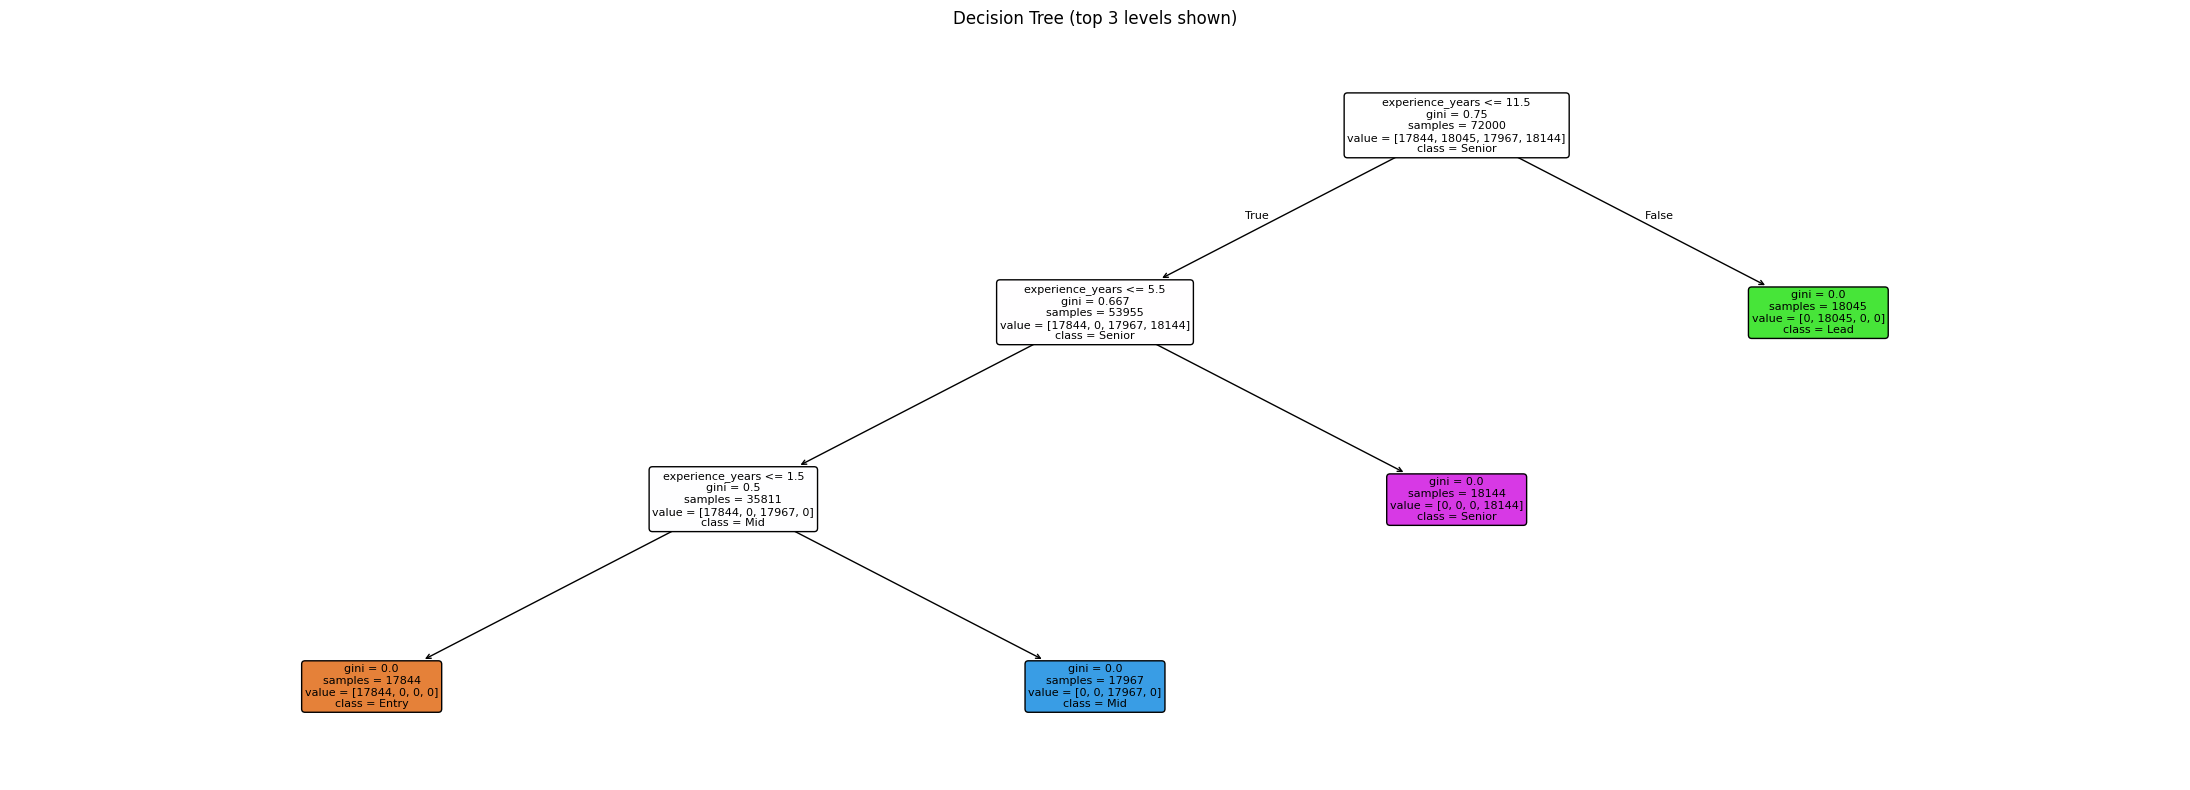

In [ ]:
plt.figure(figsize=(22, 8))
plot_tree(
    dt_model,
    max_depth=3,
    feature_names=X.columns.tolist(),
    class_names=le.classes_,
    filled=True, rounded=True, fontsize=8
)
plt.title('Decision Tree (top 3 levels shown)')
plt.tight_layout()
plt.show()

## Model 4 — Random Forest

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10,
    criterion='gini', bootstrap=True, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)   # RF does not need scaling

y_pred_rf = rf_model.predict(X_test)
evaluate_model('Random Forest', y_test, y_pred_rf)


  Random Forest
  Accuracy : 0.9971
  Precision: 0.9971  (macro)
  Recall   : 0.9970  (macro)
  F1-Score : 0.9970  (macro)

              precision    recall  f1-score   support

       Entry       1.00      0.99      1.00      4461
        Lead       1.00      1.00      1.00      4511
         Mid       0.99      1.00      0.99      4492
      Senior       1.00      1.00      1.00      4536

    accuracy                           1.00     18000
   macro avg       1.00      1.00      1.00     18000
weighted avg       1.00      1.00      1.00     18000



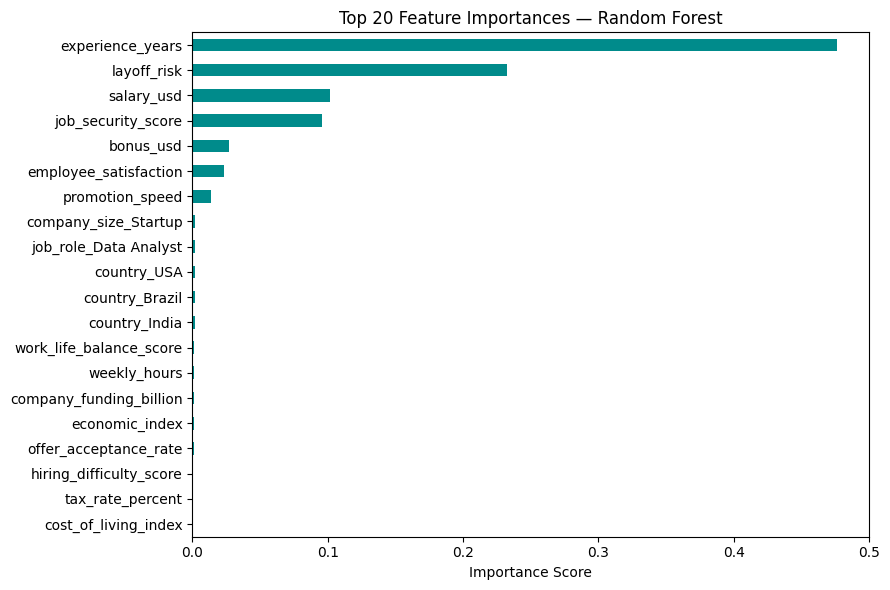

In [ ]:
# Feature importance from Random Forest
feat_imp = pd.Series(rf_model.feature_importances_, index=X.columns)
top20 = feat_imp.nlargest(20)

plt.figure(figsize=(9, 6))
top20.sort_values().plot(kind='barh', color='darkcyan')
plt.title('Top 20 Feature Importances — Random Forest')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

## Model 5 — AdaBoost

In [ ]:
ada_model = AdaBoostClassifier(
    n_estimators=200, learning_rate=0.5, random_state=42
)
ada_model.fit(X_train, y_train)   # tree-based, no scaling needed

y_pred_ada = ada_model.predict(X_test)
evaluate_model('AdaBoost', y_test, y_pred_ada)


  AdaBoost
  Accuracy : 0.4974
  Precision: 0.3329  (macro)
  Recall   : 0.5000  (macro)
  F1-Score : 0.3746  (macro)

              precision    recall  f1-score   support

       Entry       1.00      1.00      1.00      4461
        Lead       0.00      0.00      0.00      4511
         Mid       0.33      1.00      0.50      4492
      Senior       0.00      0.00      0.00      4536

    accuracy                           0.50     18000
   macro avg       0.33      0.50      0.37     18000
weighted avg       0.33      0.50      0.37     18000



---
## Model Evaluation & Comparison

All five models are compared side-by-side on Accuracy, Precision, Recall, and F1-Score (macro average).


In [ ]:
# Build comparison DataFrame
results_df = pd.DataFrame(results).T.reset_index()
results_df.columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
results_df = results_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score
      Decision Tree  1.000000   1.000000 1.000000  1.000000
Logistic Regression  0.998667   0.998663 0.998664  0.998663
      Random Forest  0.997056   0.997076 0.997034  0.997044
                KNN  0.719944   0.720524 0.720653  0.719950
           AdaBoost  0.497389   0.332946 0.500000  0.374563


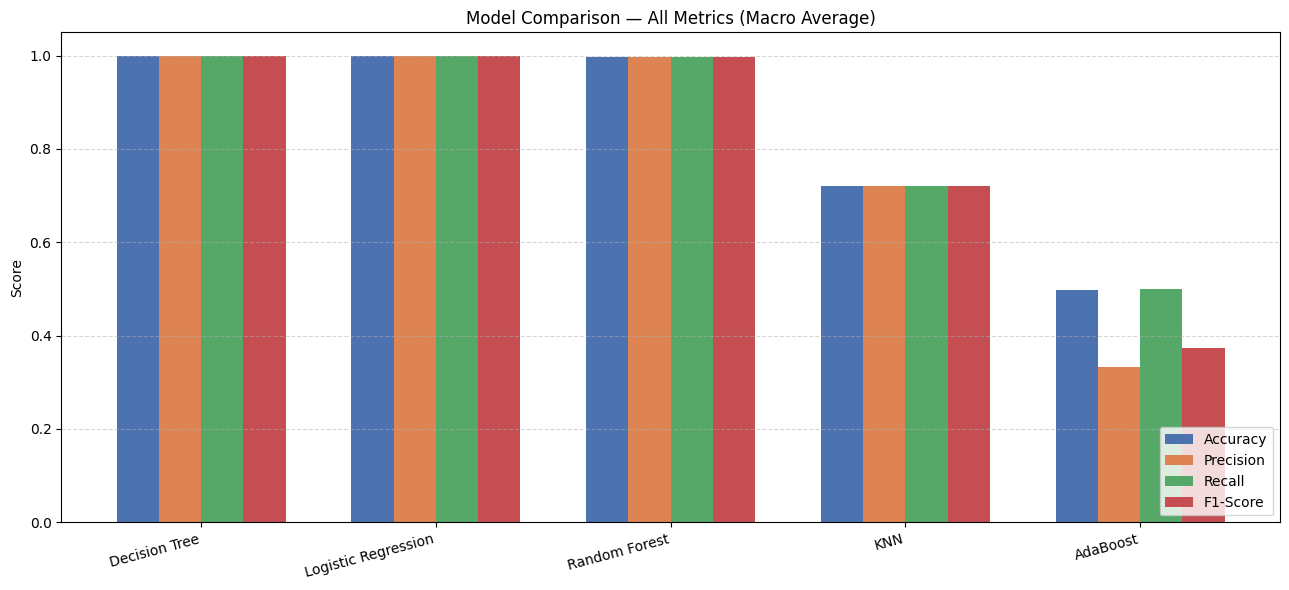

In [ ]:
# Bar chart comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(results_df))
width = 0.18
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

fig, ax = plt.subplots(figsize=(13, 6))
for i, (metric, color) in enumerate(zip(metrics, colors)):
    ax.bar(x + i * width, results_df[metric], width, label=metric, color=color)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(results_df['Model'], rotation=15, ha='right', fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Model Comparison — All Metrics (Macro Average)')
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Confusion Matrices — All Models

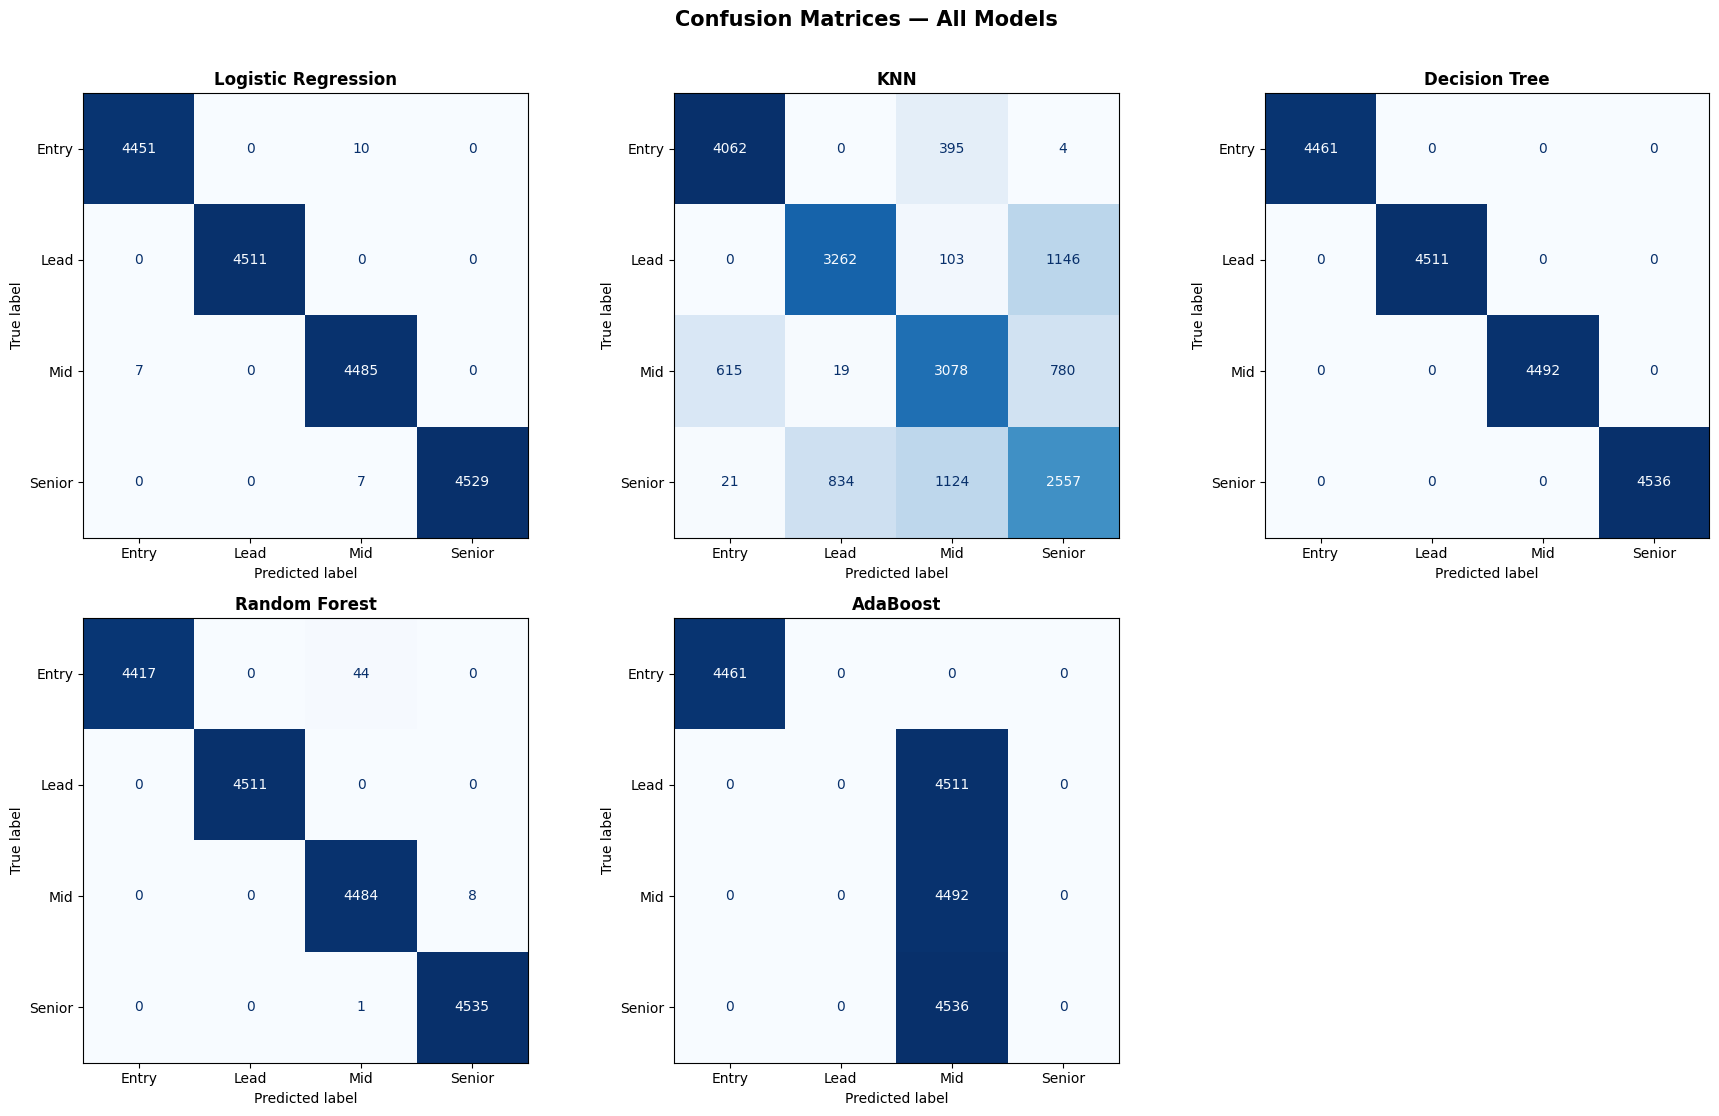

In [ ]:
all_preds = {
    'Logistic Regression': y_pred_lr,
    'KNN'                : y_pred_knn,
    'Decision Tree'      : y_pred_dt,
    'Random Forest'      : y_pred_rf,
    'AdaBoost'           : y_pred_ada,
}

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, (name, preds) in enumerate(all_preds.items()):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(ax=axes[idx], colorbar=False, cmap='Blues')
    axes[idx].set_title(f'{name}', fontsize=12, fontweight='bold')

# Hide empty 6th subplot
axes[5].set_visible(False)

plt.suptitle('Confusion Matrices — All Models', fontsize=15, y=1.01, fontweight='bold')
plt.tight_layout()
plt.show()

### Per-Class F1-Score Heatmap

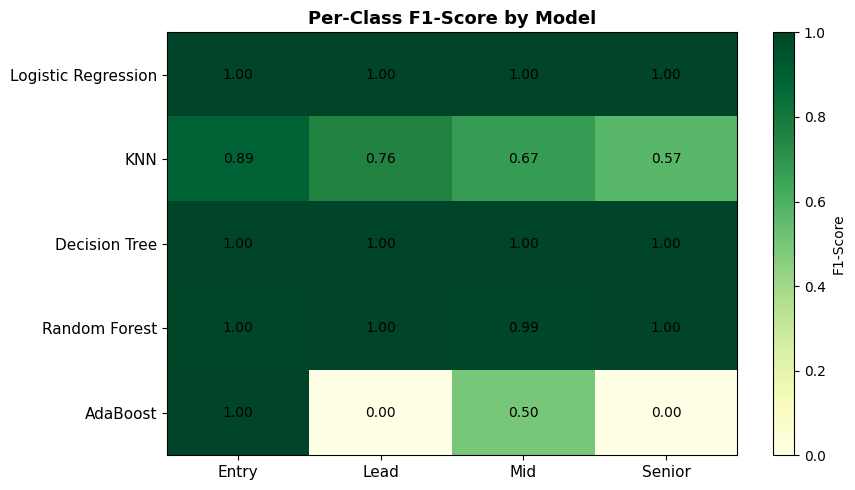

In [ ]:
class_f1 = {}
for name, preds in all_preds.items():
    scores = f1_score(y_test, preds, average=None, zero_division=0, labels=[0,1,2,3])
    class_f1[name] = scores

heatmap_df = pd.DataFrame(class_f1, index=le.classes_).T

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(heatmap_df.values, cmap='YlGn', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(le.classes_)))
ax.set_xticklabels(le.classes_, fontsize=11)
ax.set_yticks(range(len(heatmap_df)))
ax.set_yticklabels(heatmap_df.index, fontsize=11)
plt.colorbar(im, ax=ax, label='F1-Score')
ax.set_title('Per-Class F1-Score by Model', fontsize=13, fontweight='bold')

for i in range(len(heatmap_df)):
    for j in range(len(le.classes_)):
        ax.text(j, i, f"{heatmap_df.values[i, j]:.2f}",
                ha='center', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()

### Best Model Deep-Dive — Learning Curve

Best model: Decision Tree


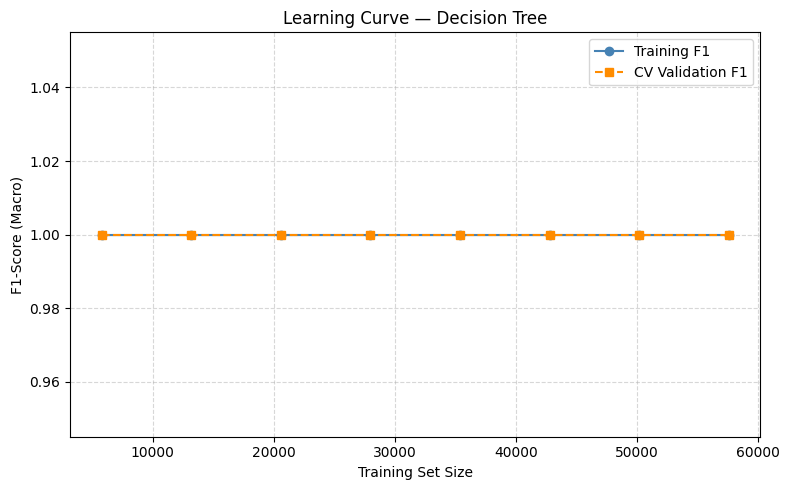

In [ ]:
best_name = results_df.iloc[0]['Model']
model_map = {
    'Logistic Regression': (lr_model, X_train_sc, X_test_sc),
    'KNN'                : (knn_model, X_train_sc, X_test_sc),
    'Decision Tree'      : (dt_model,  X_train,    X_test),
    'Random Forest'      : (rf_model,  X_train,    X_test),
    'AdaBoost'           : (ada_model, X_train,    X_test),
}

best_model, X_tr_best, _ = model_map[best_name]
print(f"Best model: {best_name}")

train_sizes, train_scores, val_scores = learning_curve(
    best_model, X_tr_best, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=5,
    scoring='f1_macro', n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
val_mean   = val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Training F1')
plt.plot(train_sizes, val_mean,   's--', color='darkorange', label='CV Validation F1')
plt.fill_between(train_sizes,
                 train_scores.min(axis=1), train_scores.max(axis=1),
                 alpha=0.1, color='steelblue')
plt.fill_between(train_sizes,
                 val_scores.min(axis=1), val_scores.max(axis=1),
                 alpha=0.1, color='darkorange')
plt.xlabel('Training Set Size')
plt.ylabel('F1-Score (Macro)')
plt.title(f'Learning Curve — {best_name}')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Overfitting Check & fix

In [ ]:
model_map_full = {
    'Logistic Regression': (lr_model,  X_train_sc, X_test_sc),
    'KNN':                 (knn_model, X_train_sc, X_test_sc),
    'Decision Tree':       (dt_model,  X_train,    X_test),
    'Random Forest':       (rf_model,  X_train,    X_test),
    'AdaBoost':            (ada_model, X_train,    X_test),
}

print(f"{'Model':<25} {'Train Acc':>10} {'Test Acc':>10} {'Gap':>8}  Status")
print('-' * 65)
overfit_flags = {}
for name, (model, Xtr, Xte) in model_map_full.items():
    tr = accuracy_score(y_train, model.predict(Xtr))
    te = accuracy_score(y_test,  model.predict(Xte))
    gap = tr - te
    overfit = gap > 0.05
    overfit_flags[name] = overfit
    status = '⚠ OVERFITTING' if overfit else '✓ OK'
    print(f"{name:<25} {tr:>10.4f} {te:>10.4f} {gap:>+8.4f}  {status}")

Model                      Train Acc   Test Acc      Gap  Status
-----------------------------------------------------------------
Logistic Regression           0.9983     0.9987  -0.0004  ✓ OK
KNN                           0.7721     0.7199  +0.0521  ⚠ OVERFITTING
Decision Tree                 1.0000     1.0000  +0.0000  ✓ OK
Random Forest                 0.9983     0.9971  +0.0012  ✓ OK
AdaBoost                      0.4974     0.4974  -0.0000  ✓ OK


In [ ]:
knn_fixed = KNeighborsClassifier(n_neighbors=75, metric='euclidean')
knn_fixed.fit(X_train_sc, y_train)

dt_fixed = DecisionTreeClassifier(criterion='gini', max_depth=5,
                                   min_samples_leaf=20, random_state=42)
dt_fixed.fit(X_train, y_train)

rf_fixed = RandomForestClassifier(n_estimators=200, max_depth=6,
                                   min_samples_leaf=20, random_state=42, n_jobs=-1)
rf_fixed.fit(X_train, y_train)

model_map_fixed = {
    'Logistic Regression':   (lr_model,  X_train_sc, X_test_sc),
    'KNN (fixed)':           (knn_fixed, X_train_sc, X_test_sc),
    'Decision Tree (fixed)': (dt_fixed,  X_train,    X_test),
    'Random Forest (fixed)': (rf_fixed,  X_train,    X_test),
    'AdaBoost':              (ada_model, X_train,    X_test),
}

print(f"{'Model':<28} {'Train Acc':>10} {'Test Acc':>10} {'Gap':>8}  Status")
print('-' * 68)
for name, (model, Xtr, Xte) in model_map_fixed.items():
    tr  = accuracy_score(y_train, model.predict(Xtr))
    te  = accuracy_score(y_test,  model.predict(Xte))
    gap = tr - te
    status = '⚠ OVERFITTING' if gap > 0.05 else '✓ OK'
    print(f"{name:<28} {tr:>10.4f} {te:>10.4f} {gap:>+8.4f}  {status}")

Model                         Train Acc   Test Acc      Gap  Status
--------------------------------------------------------------------
Logistic Regression              0.9983     0.9987  -0.0004  ✓ OK
KNN (fixed)                      0.7954     0.7623  +0.0331  ✓ OK
Decision Tree (fixed)            1.0000     1.0000  +0.0000  ✓ OK
Random Forest (fixed)            0.9805     0.9787  +0.0018  ✓ OK
AdaBoost                         0.4974     0.4974  -0.0000  ✓ OK


## ROC Curves

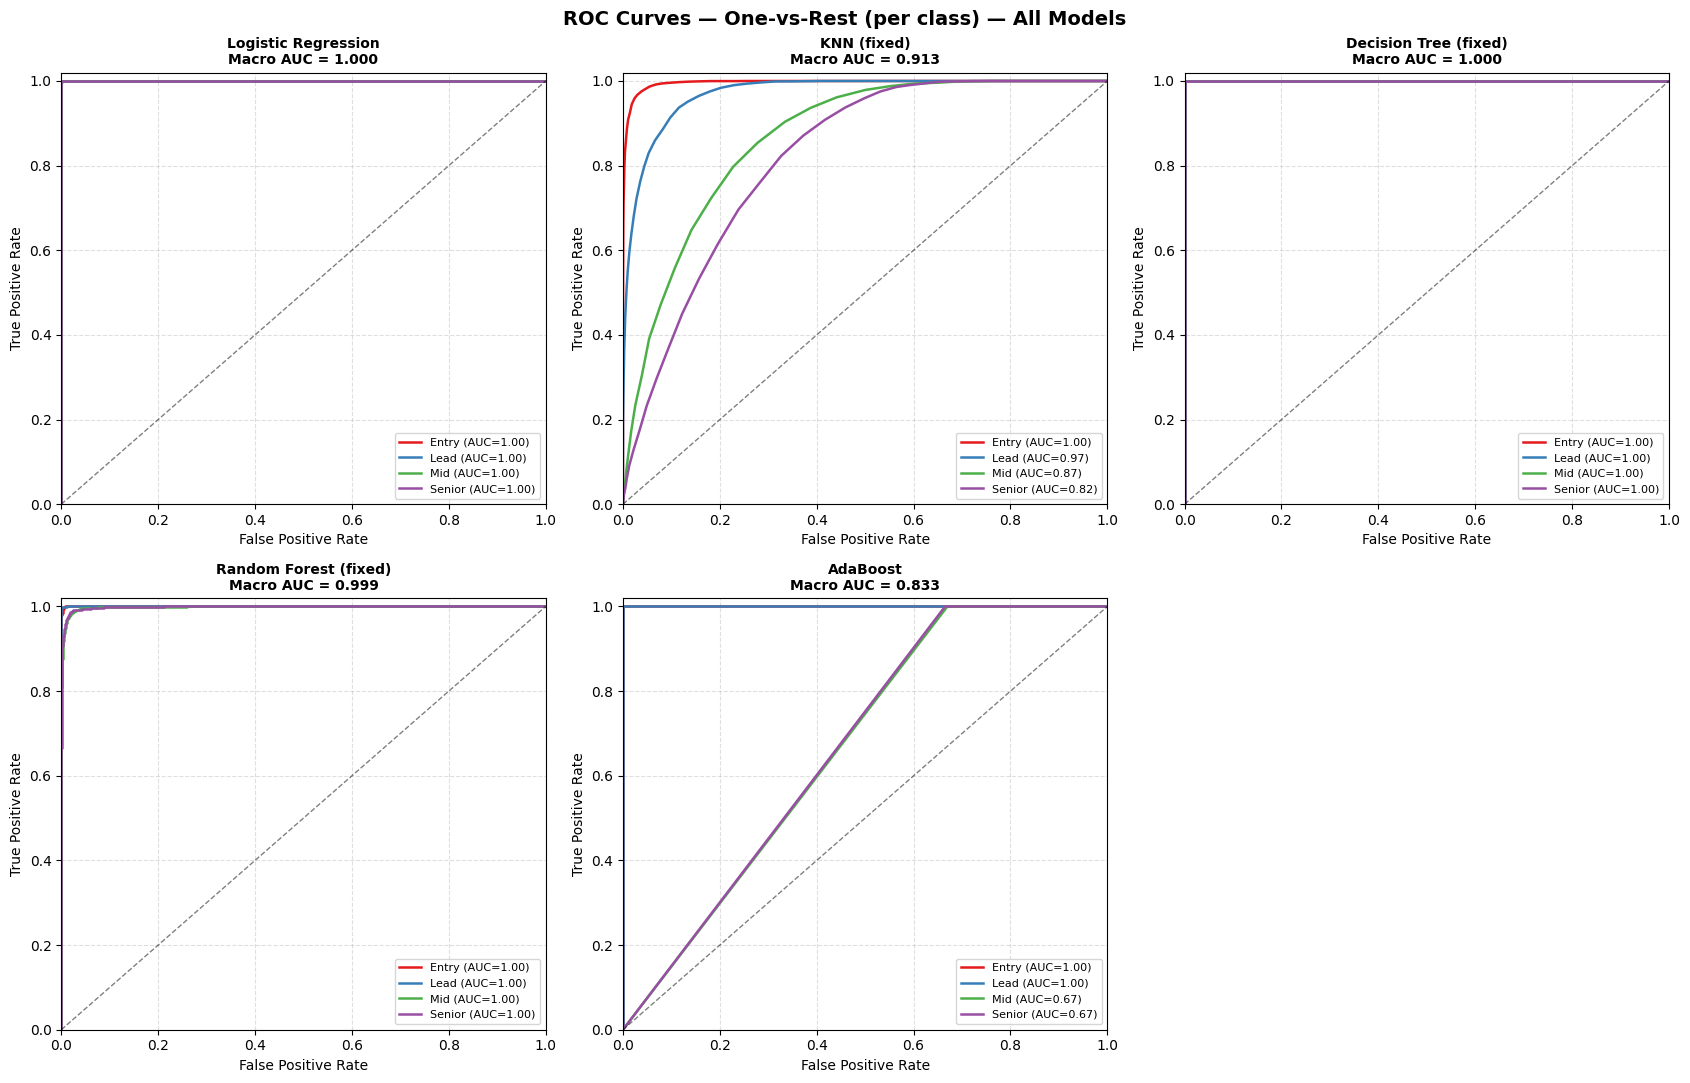

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = [0, 1, 2, 3]
y_test_bin = label_binarize(y_test, classes=classes)
colors_roc  = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
axes = axes.flatten()
fig.suptitle('ROC Curves — One-vs-Rest (per class) — All Models',
             fontsize=14, fontweight='bold')

for idx, (name, (model, _, Xte)) in enumerate(model_map_fixed.items()):
    ax = axes[idx]
    y_score = model.predict_proba(Xte)   # all sklearn models here support predict_proba
    macro_aucs = []
    for ci, color in zip(classes, colors_roc):
        fpr, tpr, _ = roc_curve(y_test_bin[:, ci], y_score[:, ci])
        roc_auc = auc(fpr, tpr)
        macro_aucs.append(roc_auc)
        ax.plot(fpr, tpr, color=color, lw=1.8,
                label=f'{le.classes_[ci]} (AUC={roc_auc:.2f})')
    ax.plot([0,1],[0,1],'k--', lw=1, alpha=0.5)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{name}\nMacro AUC = {np.mean(macro_aucs):.3f}',
                 fontsize=10, fontweight='bold')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(linestyle='--', alpha=0.4)

axes[5].set_visible(False)
plt.tight_layout()
plt.show()